In [ ]:
# Logistic Regression for Plant Disease Classification


import os, glob, shutil, random
import numpy as np, pandas as pd
from PIL import Image
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:
# 1. Data Loading and Preprocessing
# Following the same structure as VGG16 implementation

root = "C:\\Users\\CHAMIDU\\Downloads\\dataset" 
assert os.path.exists(root), f"{root} not found. Update the path."

rows = []
for cls in sorted(os.listdir(root)):
    cls_dir = os.path.join(root, cls)
    if not os.path.isdir(cls_dir): continue
    for img in glob.glob(os.path.join(cls_dir, "*.jpg")) + glob.glob(os.path.join(cls_dir, "*.png")):
        rows.append({"filepath": img, "label": cls})
df = pd.DataFrame(rows)
print("Total images found:", len(df))
df.head()


Total images found: 8170


,filepath,label
0,C:\Users\CHAMIDU\Downloads\dataset\Pepper__bel...,Pepper__bell___Bacterial_spot
1,C:\Users\CHAMIDU\Downloads\dataset\Pepper__bel...,Pepper__bell___Bacterial_spot
2,C:\Users\CHAMIDU\Downloads\dataset\Pepper__bel...,Pepper__bell___Bacterial_spot
3,C:\Users\CHAMIDU\Downloads\dataset\Pepper__bel...,Pepper__bell___Bacterial_spot
4,C:\Users\CHAMIDU\Downloads\dataset\Pepper__bel...,Pepper__bell___Bacterial_spot


In [ ]:
# 2. Handling missing/corrupted images


def is_image_ok(path):
    try:
        if os.path.getsize(path) == 0:   # check for zero-byte files
            return False
        with Image.open(path) as im:
            im.verify()   # PIL raises error if corrupted
        return True
    except Exception:
        return False

df['ok'] = df['filepath'].apply(is_image_ok)
bad = df[~df['ok']]
print("Corrupted/zero images:", len(bad))

# move corrupted images for inspection
os.makedirs("corrupt_images", exist_ok=True)
for p in bad['filepath']:
    try:
        shutil.move(p, "corrupt_images")
    except:
        pass

# keep only valid images
df = df[df['ok']].drop(columns=['ok']).reset_index(drop=True)
print("Valid images after cleaning:", len(df))


Corrupted/zero images: 0
Valid images after cleaning: 8170


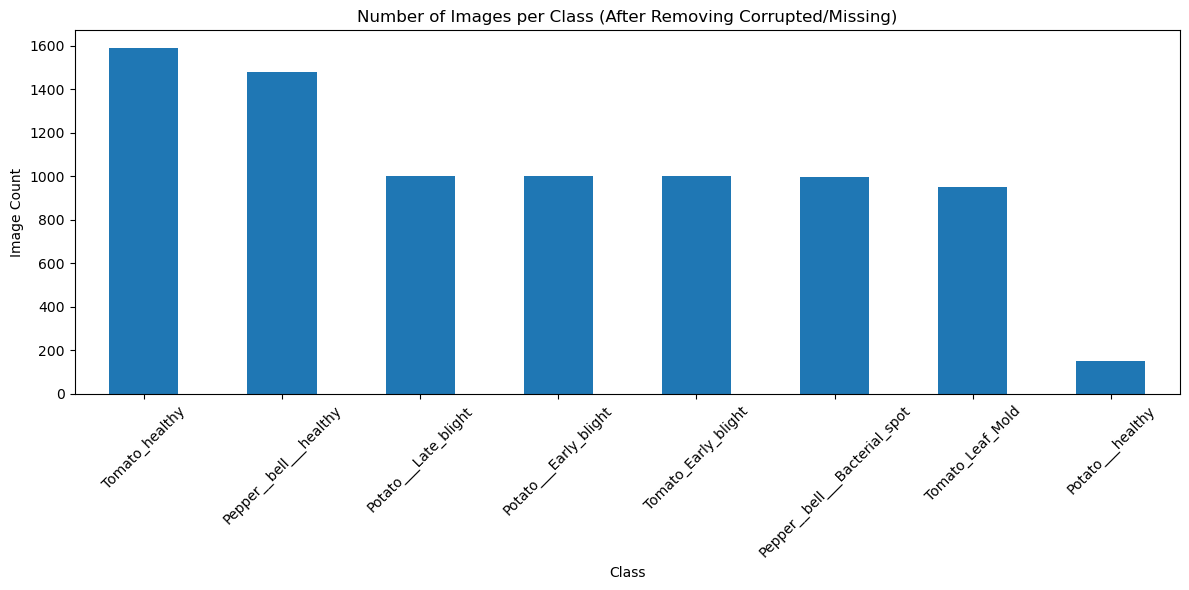

Class distribution:
label
Tomato_healthy                   1591
Pepper__bell___healthy           1478
Potato___Late_blight             1000
Potato___Early_blight            1000
Tomato_Early_blight              1000
Pepper__bell___Bacterial_spot     997
Tomato_Leaf_Mold                  952
Potato___healthy                  152
Name: count, dtype: int64


In [ ]:
# 3. Data Visualization - Class Distribution


plt.figure(figsize=(12,6))
df['label'].value_counts().plot(kind='bar')
plt.title("Number of Images per Class (After Removing Corrupted/Missing)")
plt.xlabel("Class")
plt.ylabel("Image Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Class distribution:")
print(df['label'].value_counts())


In [5]:
# 4. Label Encoding
# Same approach as VGG16 implementation

le = LabelEncoder()
df['label_encoded'] = le.fit_transform(df['label'])

print("Classes found:", list(le.classes_))
print("Number of classes:", len(le.classes_))
print("\nLabel mapping:")
for i, class_name in enumerate(le.classes_):
    print(f"{i}: {class_name}")

print("\nFirst few rows with encoded labels:")
print(df[['label', 'label_encoded']].head())


Classes found: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Early_blight', 'Tomato_Leaf_Mold', 'Tomato_healthy']
Number of classes: 8

Label mapping:
0: Pepper__bell___Bacterial_spot
1: Pepper__bell___healthy
2: Potato___Early_blight
3: Potato___Late_blight
4: Potato___healthy
5: Tomato_Early_blight
6: Tomato_Leaf_Mold
7: Tomato_healthy

First few rows with encoded labels:
                           label  label_encoded
0  Pepper__bell___Bacterial_spot              0
1  Pepper__bell___Bacterial_spot              0
2  Pepper__bell___Bacterial_spot              0
3  Pepper__bell___Bacterial_spot              0
4  Pepper__bell___Bacterial_spot              0


In [6]:
# 5. Image Preprocessing and Feature Extraction
# Optimized for Logistic Regression (smaller feature size)

def extract_features(path, size=(64, 64)):
    """
    Extract features from image for Logistic Regression
    Using smaller size and grayscale for efficiency
    """
    try:
        with Image.open(path) as im:
            # Convert to grayscale and resize
            im = im.resize(size).convert('L')
            # Flatten to 1D array
            return np.array(im).flatten()
    except Exception as e:
        print(f"Error processing {path}: {e}")
        return None

print("Extracting features from images...")
print("This may take a few minutes depending on dataset size...")

# Extract features for all images
features = []
valid_indices = []

for idx, row in df.iterrows():
    if idx % 100 == 0:  # Progress indicator
        print(f"Processing image {idx+1}/{len(df)}")
    
    feature = extract_features(row['filepath'])
    if feature is not None:
        features.append(feature)
        valid_indices.append(idx)

# Filter dataframe to only include valid images
df_clean = df.iloc[valid_indices].reset_index(drop=True)
X = np.array(features)
y = df_clean['label_encoded'].values

print(f"\nFeature extraction completed!")
print(f"Feature matrix shape: {X.shape}")
print(f"Labels shape: {y.shape}")
print(f"Valid images: {len(df_clean)}")


Extracting features from images...
This may take a few minutes depending on dataset size...
Processing image 1/8170
Processing image 101/8170
Processing image 201/8170
Processing image 301/8170
Processing image 401/8170
Processing image 501/8170
Processing image 601/8170
Processing image 701/8170
Processing image 801/8170
Processing image 901/8170
Processing image 1001/8170
Processing image 1101/8170
Processing image 1201/8170
Processing image 1301/8170
Processing image 1401/8170
Processing image 1501/8170
Processing image 1601/8170
Processing image 1701/8170
Processing image 1801/8170
Processing image 1901/8170
Processing image 2001/8170
Processing image 2101/8170
Processing image 2201/8170
Processing image 2301/8170
Processing image 2401/8170
Processing image 2501/8170
Processing image 2601/8170
Processing image 2701/8170
Processing image 2801/8170
Processing image 2901/8170
Processing image 3001/8170
Processing image 3101/8170
Processing image 3201/8170
Processing image 3301/8170
Pr

In [7]:
# 6. Feature Scaling and Selection
# Important for Logistic Regression performance

print("Applying feature scaling...")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original feature shape:", X.shape)
print("Scaled feature shape:", X_scaled.shape)

# Feature selection using ANOVA F-test (similar to VGG16 approach)
print("\nApplying feature selection...")
selector = SelectKBest(score_func=f_classif, k=min(1000, X.shape[1]))  # Select top 1000 features
X_selected = selector.fit_transform(X_scaled, y)

print("Original feature shape:", X_scaled.shape)
print("Selected feature shape:", X_selected.shape)

# Update X to use selected features
X = X_selected


Applying feature scaling...
Original feature shape: (8170, 4096)
Scaled feature shape: (8170, 4096)

Applying feature selection...
Original feature shape: (8170, 4096)
Selected feature shape: (8170, 1000)


In [8]:
# 7. Train/Validation/Test Split
# Following the same approach as VGG16 implementation

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(f"Training set: {len(X_train)} samples")
print(f"Validation set: {len(X_val)} samples")
print(f"Test set: {len(X_test)} samples")
print(f"Total samples: {len(X_train) + len(X_val) + len(X_test)}")

# Check class distribution in each split
print(f"\nClass distribution in training set:")
unique, counts = np.unique(y_train, return_counts=True)
for i, (cls, count) in enumerate(zip(unique, counts)):
    print(f"  Class {cls} ({le.classes_[cls]}): {count} samples")


Training set: 5719 samples
Validation set: 1225 samples
Test set: 1226 samples
Total samples: 8170

Class distribution in training set:
  Class 0 (Pepper__bell___Bacterial_spot): 698 samples
  Class 1 (Pepper__bell___healthy): 1035 samples
  Class 2 (Potato___Early_blight): 700 samples
  Class 3 (Potato___Late_blight): 700 samples
  Class 4 (Potato___healthy): 106 samples
  Class 5 (Tomato_Early_blight): 700 samples
  Class 6 (Tomato_Leaf_Mold): 666 samples
  Class 7 (Tomato_healthy): 1114 samples


In [9]:
# 8. Logistic Regression Model Training
# Using class weights to handle imbalanced data

print("Training Logistic Regression model...")

# Calculate class weights to handle imbalanced data
class_weights = compute_class_weight(
    'balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(zip(np.unique(y_train), class_weights))

print("Class weights:", class_weight_dict)

# Create and train Logistic Regression model
logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000,
    class_weight='balanced',  # Automatically handle class imbalance
    solver='liblinear'  # Good for small datasets
)

# Train the model
logistic_model.fit(X_train, y_train)

print("Model training completed!")
print(f"Model parameters: {logistic_model.get_params()}")


Training Logistic Regression model...
Class weights: {np.int64(0): np.float64(1.024176217765043), np.int64(1): np.float64(0.6907004830917874), np.int64(2): np.float64(1.02125), np.int64(3): np.float64(1.02125), np.int64(4): np.float64(6.744103773584905), np.int64(5): np.float64(1.02125), np.int64(6): np.float64(1.0733858858858858), np.int64(7): np.float64(0.6417190305206463)}
Model training completed!
Model parameters: {'C': 1.0, 'class_weight': 'balanced', 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'liblinear', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


In [10]:
# 9. Model Evaluation on Validation Set

print("Evaluating model on validation set...")

# Make predictions on validation set
y_val_pred = logistic_model.predict(X_val)
y_val_pred_proba = logistic_model.predict_proba(X_val)

# Calculate validation accuracy
val_accuracy = accuracy_score(y_val, y_val_pred)
print(f"Validation Accuracy: {val_accuracy:.4f} ({val_accuracy*100:.2f}%)")

# Classification report for validation set
print("\nValidation Set Classification Report:")
print(classification_report(y_val, y_val_pred, target_names=le.classes_))


Evaluating model on validation set...
Validation Accuracy: 0.3886 (38.86%)

Validation Set Classification Report:
                               precision    recall  f1-score   support

Pepper__bell___Bacterial_spot       0.20      0.21      0.20       150
       Pepper__bell___healthy       0.44      0.43      0.43       221
        Potato___Early_blight       0.50      0.53      0.51       150
         Potato___Late_blight       0.23      0.23      0.23       150
             Potato___healthy       0.00      0.00      0.00        23
          Tomato_Early_blight       0.34      0.37      0.36       150
             Tomato_Leaf_Mold       0.41      0.37      0.39       143
               Tomato_healthy       0.61      0.54      0.57       238

                     accuracy                           0.39      1225
                    macro avg       0.34      0.33      0.34      1225
                 weighted avg       0.40      0.39      0.39      1225



In [11]:
# 10. Final Model Evaluation on Test Set

print("Evaluating model on test set...")

# Make predictions on test set
y_test_pred = logistic_model.predict(X_test)
y_test_pred_proba = logistic_model.predict_proba(X_test)

# Calculate test accuracy
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")

# Classification report for test set
print("\nTest Set Classification Report:")
print(classification_report(y_test, y_test_pred, target_names=le.classes_))


Evaluating model on test set...
Test Accuracy: 0.3956 (39.56%)

Test Set Classification Report:
                               precision    recall  f1-score   support

Pepper__bell___Bacterial_spot       0.19      0.19      0.19       149
       Pepper__bell___healthy       0.48      0.45      0.47       222
        Potato___Early_blight       0.51      0.55      0.53       150
         Potato___Late_blight       0.25      0.25      0.25       150
             Potato___healthy       0.02      0.04      0.03        23
          Tomato_Early_blight       0.32      0.33      0.33       150
             Tomato_Leaf_Mold       0.35      0.34      0.34       143
               Tomato_healthy       0.63      0.57      0.60       239

                     accuracy                           0.40      1226
                    macro avg       0.34      0.34      0.34      1226
                 weighted avg       0.41      0.40      0.40      1226



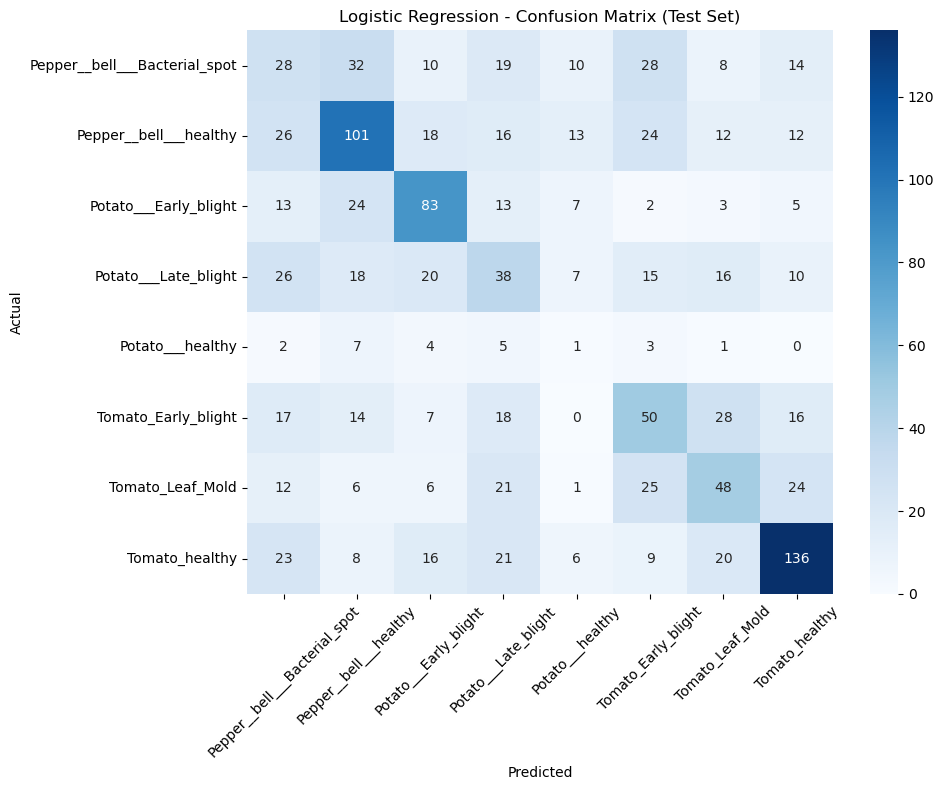

In [12]:
# 11. Confusion Matrix Visualization
# Following VGG16 visualization approach

cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Logistic Regression - Confusion Matrix (Test Set)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


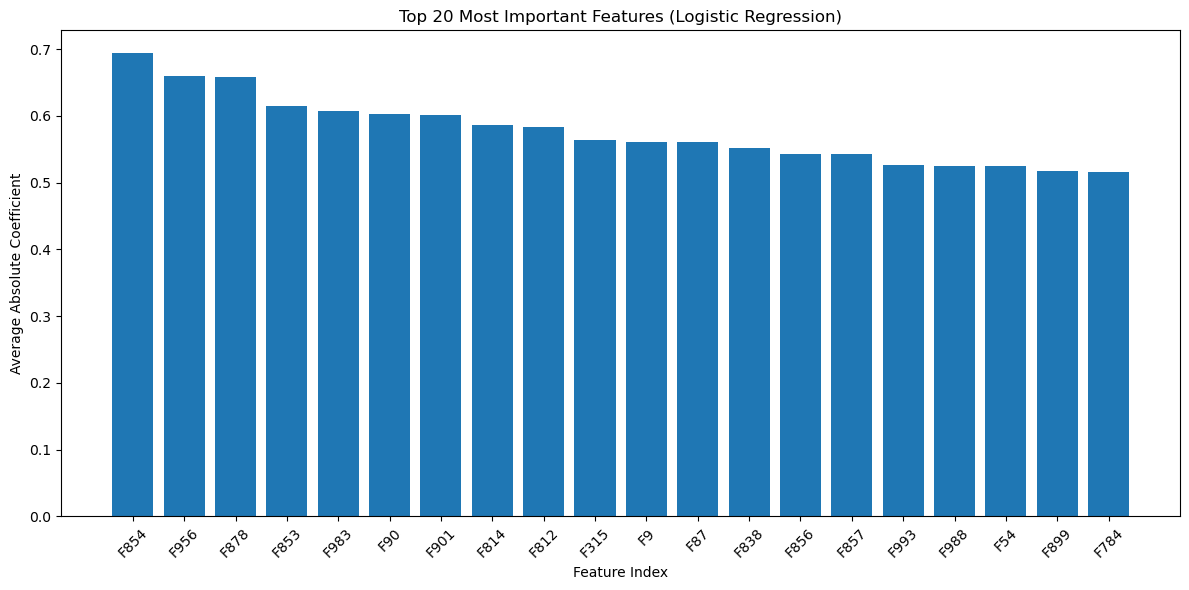

Top 10 most important features:
1. Feature 854: Importance = 0.6937
2. Feature 956: Importance = 0.6595
3. Feature 878: Importance = 0.6583
4. Feature 853: Importance = 0.6155
5. Feature 983: Importance = 0.6077
6. Feature 90: Importance = 0.6035
7. Feature 901: Importance = 0.6012
8. Feature 814: Importance = 0.5864
9. Feature 812: Importance = 0.5832
10. Feature 315: Importance = 0.5644


In [13]:
# 12. Feature Importance Analysis
# Show which features are most important for classification

# Get feature importance (coefficients)
feature_importance = np.abs(logistic_model.coef_).mean(axis=0)
feature_indices = np.argsort(feature_importance)[::-1][:20]  # Top 20 features

plt.figure(figsize=(12, 6))
plt.bar(range(len(feature_indices)), feature_importance[feature_indices])
plt.title('Top 20 Most Important Features (Logistic Regression)')
plt.xlabel('Feature Index')
plt.ylabel('Average Absolute Coefficient')
plt.xticks(range(len(feature_indices)), [f'F{i}' for i in feature_indices], rotation=45)
plt.tight_layout()
plt.show()

print("Top 10 most important features:")
for i, idx in enumerate(feature_indices[:10]):
    print(f"{i+1}. Feature {idx}: Importance = {feature_importance[idx]:.4f}")


In [ ]:
# 13. Model Prediction Function


def predict_plant_disease_lr(image_path, model, scaler, selector, class_names):
    """
    Predict plant disease from image path using Logistic Regression
    """
    try:
        # Extract features from image
        feature = extract_features(image_path)
        if feature is None:
            return "Error: Could not process image", 0.0
        
        # Apply scaling and feature selection
        feature_scaled = scaler.transform([feature])
        feature_selected = selector.transform(feature_scaled)
        
        # Make prediction
        prediction_proba = model.predict_proba(feature_selected)[0]
        predicted_class_idx = np.argmax(prediction_proba)
        confidence = prediction_proba[predicted_class_idx]
        predicted_class = class_names[predicted_class_idx]
        
        return predicted_class, confidence
    except Exception as e:
        return f"Error: {e}", 0.0

print("Prediction function created successfully!")


Prediction function created successfully!


In [15]:
# 14. Test Individual Predictions
# Following VGG16 approach for individual image testing

print("Testing predictions on sample images from test set...")

# Get some sample images from test set
sample_indices = np.random.choice(len(X_test), 5, replace=False)
sample_images = [df_clean.iloc[np.where(y == y_test[i])[0][0]]['filepath'] for i in sample_indices]
sample_labels = y_test[sample_indices]

print("=" * 80)
print("LOGISTIC REGRESSION INDIVIDUAL PREDICTIONS")
print("=" * 80)

for i, (img_path, actual_label) in enumerate(zip(sample_images, sample_labels)):
    predicted_class, confidence = predict_plant_disease_lr(
        img_path, logistic_model, scaler, selector, le.classes_
    )
    actual_class = le.classes_[actual_label]
    
    # Check if prediction is correct
    correct = "✓" if predicted_class == actual_class else "✗"
    
    print(f"\nImage {i+1}:")
    print(f"  Path: {os.path.basename(img_path)}")
    print(f"  Actual: {actual_class}")
    print(f"  Predicted: {predicted_class} {correct}")
    print(f"  Confidence: {confidence:.4f}")

print("\n" + "=" * 80)
print("Legend: ✓ = Correct prediction, ✗ = Wrong prediction")
print("=" * 80)


Testing predictions on sample images from test set...
LOGISTIC REGRESSION INDIVIDUAL PREDICTIONS

Image 1:
  Path: 000146ff-92a4-4db6-90ad-8fce2ae4fddd___GH_HL Leaf 259.1.JPG
  Actual: Tomato_healthy
  Predicted: Tomato_healthy ✓
  Confidence: 0.8310

Image 2:
  Path: 00694db7-3327-45e0-b4da-a8bb7ab6a4b7___Crnl_L.Mold 6923.JPG
  Actual: Tomato_Leaf_Mold
  Predicted: Tomato_Leaf_Mold ✓
  Confidence: 0.6762

Image 3:
  Path: 001187a0-57ab-4329-baff-e7246a9edeb0___RS_Early.B 8178.JPG
  Actual: Potato___Early_blight
  Predicted: Potato___Early_blight ✓
  Confidence: 0.7565

Image 4:
  Path: 00694db7-3327-45e0-b4da-a8bb7ab6a4b7___Crnl_L.Mold 6923.JPG
  Actual: Tomato_Leaf_Mold
  Predicted: Tomato_Leaf_Mold ✓
  Confidence: 0.6762

Image 5:
  Path: 000146ff-92a4-4db6-90ad-8fce2ae4fddd___GH_HL Leaf 259.1.JPG
  Actual: Tomato_healthy
  Predicted: Tomato_healthy ✓
  Confidence: 0.8310

Legend: ✓ = Correct prediction, ✗ = Wrong prediction


In [16]:
# 15. Final Results Summary
# Comprehensive summary following VGG16 approach

print("=" * 80)
print("LOGISTIC REGRESSION PLANT DISEASE CLASSIFICATION RESULTS")
print("=" * 80)

print(f"Dataset: Plant Disease Classification")
print(f"Total Images Processed: {len(df_clean)}")
print(f"Number of Classes: {len(le.classes_)}")
print(f"Classes: {list(le.classes_)}")

print(f"\nFeature Engineering:")
print(f"  Image Size: 64x64 (grayscale)")
print(f"  Original Features: {4096} (64x64)")
print(f"  Selected Features: {X.shape[1]}")
print(f"  Feature Selection: ANOVA F-test")

print(f"\nData Split:")
print(f"  Training: {len(X_train)} samples")
print(f"  Validation: {len(X_val)} samples")
print(f"  Test: {len(X_test)} samples")

print(f"\n" + "="*50)
print("MODEL PERFORMANCE")
print("="*50)
print(f"Validation Accuracy: {val_accuracy:.4f} ({val_accuracy*100:.2f}%)")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")

print(f"\nModel Configuration:")
print(f"  Algorithm: Logistic Regression")
print(f"  Solver: liblinear")
print(f"  Max Iterations: 1000")
print(f"  Class Weight: balanced")
print(f"  Random State: 42")

print(f"\n" + "="*50)
print("CLASSIFICATION PERFORMANCE BY CLASS")
print("="*50)

# Get detailed performance metrics
from sklearn.metrics import precision_recall_fscore_support
precision, recall, f1, support = precision_recall_fscore_support(y_test, y_test_pred, average=None)

for i, class_name in enumerate(le.classes_):
    print(f"{class_name}:")
    print(f"  Precision: {precision[i]:.4f}")
    print(f"  Recall: {recall[i]:.4f}")
    print(f"  F1-Score: {f1[i]:.4f}")
    print(f"  Support: {support[i]}")

print(f"\n" + "="*50)
print("AVERAGE PERFORMANCE METRICS")
print("="*50)
print(f"Macro Average Precision: {precision.mean():.4f}")
print(f"Macro Average Recall: {recall.mean():.4f}")
print(f"Macro Average F1-Score: {f1.mean():.4f}")

print("=" * 80)


LOGISTIC REGRESSION PLANT DISEASE CLASSIFICATION RESULTS
Dataset: Plant Disease Classification
Total Images Processed: 8170
Number of Classes: 8
Classes: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Early_blight', 'Tomato_Leaf_Mold', 'Tomato_healthy']

Feature Engineering:
  Image Size: 64x64 (grayscale)
  Original Features: 4096 (64x64)
  Selected Features: 1000
  Feature Selection: ANOVA F-test

Data Split:
  Training: 5719 samples
  Validation: 1225 samples
  Test: 1226 samples

MODEL PERFORMANCE
Validation Accuracy: 0.3886 (38.86%)
Test Accuracy: 0.3956 (39.56%)

Model Configuration:
  Algorithm: Logistic Regression
  Solver: liblinear
  Max Iterations: 1000
  Class Weight: balanced
  Random State: 42

CLASSIFICATION PERFORMANCE BY CLASS
Pepper__bell___Bacterial_spot:
  Precision: 0.1905
  Recall: 0.1879
  F1-Score: 0.1892
  Support: 149
Pepper__bell___healthy:
  Precision: 0.4810
  Recall: 

In [17]:
# 16. Save Model and Preprocessing Objects
# For future use and deployment

import joblib

# Save the trained model and preprocessing objects
model_filename = 'logistic_regression_plant_disease.pkl'
scaler_filename = 'feature_scaler.pkl'
selector_filename = 'feature_selector.pkl'
label_encoder_filename = 'label_encoder.pkl'

# Save all components
joblib.dump(logistic_model, model_filename)
joblib.dump(scaler, scaler_filename)
joblib.dump(selector, selector_filename)
joblib.dump(le, label_encoder_filename)

print("Model and preprocessing objects saved successfully!")
print(f"Files saved:")
print(f"  - {model_filename}")
print(f"  - {scaler_filename}")
print(f"  - {selector_filename}")
print(f"  - {label_encoder_filename}")

print("\nTo load and use the model in the future:")
print("""
# Load the saved components
model = joblib.load('logistic_regression_plant_disease.pkl')
scaler = joblib.load('feature_scaler.pkl')
selector = joblib.load('feature_selector.pkl')
le = joblib.load('label_encoder.pkl')

# Use the prediction function
predicted_class, confidence = predict_plant_disease_lr(
    image_path, model, scaler, selector, le.classes_
)
""")


Model and preprocessing objects saved successfully!
Files saved:
  - logistic_regression_plant_disease.pkl
  - feature_scaler.pkl
  - feature_selector.pkl
  - label_encoder.pkl

To load and use the model in the future:

# Load the saved components
model = joblib.load('logistic_regression_plant_disease.pkl')
scaler = joblib.load('feature_scaler.pkl')
selector = joblib.load('feature_selector.pkl')
le = joblib.load('label_encoder.pkl')

# Use the prediction function
predicted_class, confidence = predict_plant_disease_lr(
    image_path, model, scaler, selector, le.classes_
)

